### Drive Mounting

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Importing the Libraries

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import zipfile
import os

import statsmodels.api as sm
from statsmodels.formula.api import ols

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score , root_mean_squared_error


### Extracting the data

In [3]:
#zip_path = '/content/drive/MyDrive/home_data_for_ml_course.zip'

def extract_dataset(zip_path , save_path = '/content/Ames_Dataset'):
  os.makedirs(save_path , exist_ok= True)

  with zipfile.ZipFile(zip_path , 'r') as zip_ref:
    zip_ref.extractall(save_path)
    print(f'The dataset is successfully extracted and save to : {save_path}')
  return os.listdir(save_path)


In [4]:
files = extract_dataset('/content/drive/MyDrive/home_data_for_ml_course.zip')
print(files)

The dataset is successfully extracted and save to : /content/Ames_Dataset
['train.csv', 'test.csv.gz', 'data_description.txt', 'sample_submission.csv', 'sample_submission.csv.gz', 'train.csv.gz', 'test.csv']


### Loading the Data

In [5]:
Ames_data = pd.read_csv('/content/Ames_Dataset/train.csv')
Ames_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
Ames_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
Ames_data.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


### Data Cleaning

In [ ]:
pd.set_option('display.max_rows' , None)
Ames_data.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
Street,0
Alley,1369
LotShape,0
LandContour,0
Utilities,0


### handling Missing Data

In the data description, most of the missing values are not missing values or errors it simply means that the house do not have that specific feature. Except from the columns: LotFrontage , and Electrical which really have real missing values.

The other colomns except from the two will be fill with "None" .

LotFrontage missing values will be fill with the median of all houses grouped by the Neighborhood to get a value close to the real one

Electrical missing value will be fill with the mode of the houses based on the age of the houses.

In [6]:
# Fill the missing values with None

None_columns = ['Alley', 'MasVnrType', 'MasVnrArea', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish',
       'GarageQual', 'GarageCond', 'PoolQC', 'Fence' , 'MiscFeature']
Ames_data[None_columns] = Ames_data[None_columns].fillna('None')

# Fill the LotFrontage with the median of all houses based on their neighborhood.

Ames_data['LotFrontage'] = Ames_data['LotFrontage'].fillna(
    Ames_data.groupby('Neighborhood')['LotFrontage'].transform('median'))

# Fill the 1 row missing value of the Electrical column based on the year of built

Ames_data['Electrical'] = Ames_data['Electrical'].fillna(
    Ames_data.groupby('MSSubClass')['Electrical'].transform(
        lambda x : x.mode()[0] if not x.mode().empty else 'SBrkr'
        )
)

In [7]:
Ames_data.isnull().sum().sum()

np.int64(0)

In [8]:
# Check for duplicates

Ames_data.duplicated().any()

np.False_

### Exploratory Data Analysis

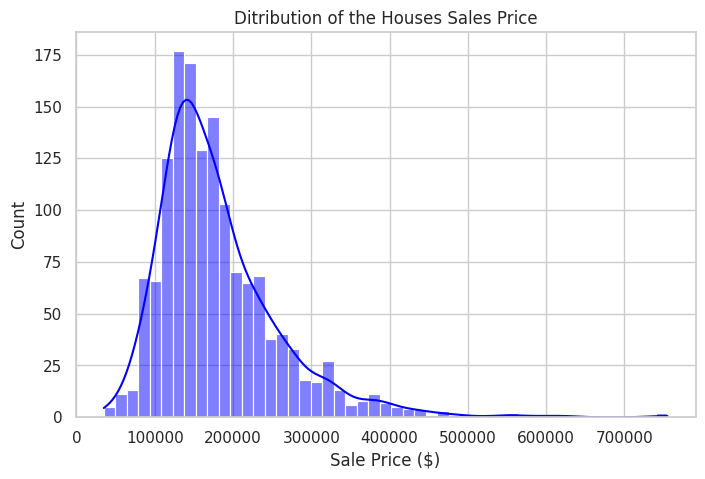

In [9]:
sns.set_theme(style = 'whitegrid')

# Plot the distribution of the SalePrices

plt.figure(figsize= (8 , 5))
sns.histplot(Ames_data['SalePrice'] , kde=True , color='blue')
plt.title('Ditribution of the Houses Sales Price')
plt.xlabel('Sale Price ($)')
plt.ylabel('Count')
plt.show()

We can see that the peak tells us that the most common house prices are between $135,000 and $185,000

Also , the Sales price is right skewed with some outliers which goes from $600,000 to $700,000 and plus. This can make the average house price extremely high.

we are going to perform log transformation on the Saleprice feature

In [24]:
Ames_data['LogSalePrice'] = np.log1p(Ames_data['SalePrice'])

/tmp/ipykernel_1340/848670814.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Ames_data['LogSalePrice'] = np.log1p(Ames_data['SalePrice'])


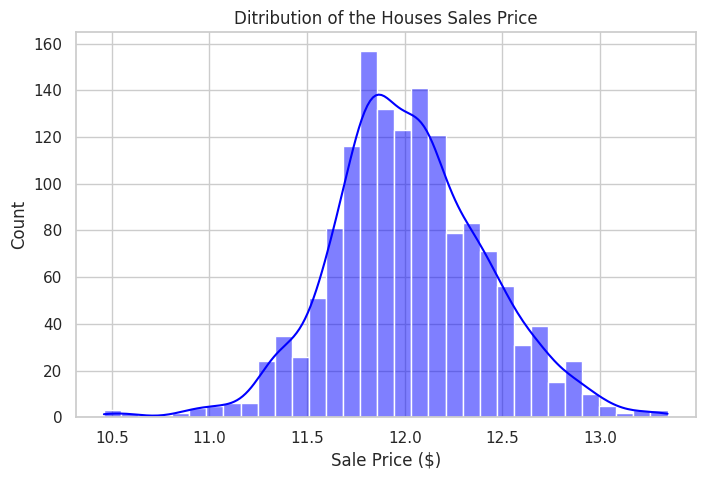

In [25]:
# Plot the distribution of the SalePrices

plt.figure(figsize= (8 , 5))
sns.histplot(Ames_data['LogSalePrice'] , kde=True , color='blue')
plt.title('Ditribution of the Houses Sales Price')
plt.xlabel('Sale Price ($)')
plt.ylabel('Count')
plt.show()

In [17]:
from numpy._core.numerictypes import float64
# lets find the features wich are strongly correlated to the Sales Price.

# Claculation the Correlation matrix for the numerical columns

num_cols = Ames_data.select_dtypes(include=['int64' , 'float64'])
corr_matrix = num_cols.corr()

# sort them to see the top ones
top_corr = corr_matrix['SalePrice'].sort_values(ascending=False)

print(f'Top 20 features correlated with the SalePrice : {top_corr.head(20)}')

Top 20 features correlated with the SalePrice : SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Fireplaces      0.466929
BsmtFinSF1      0.386420
LotFrontage     0.349876
WoodDeckSF      0.324413
2ndFlrSF        0.319334
OpenPorchSF     0.315856
HalfBath        0.284108
LotArea         0.263843
BsmtFullBath    0.227122
Name: SalePrice, dtype: float64


In [20]:
from __future__ import print_function
# Check the most correlated categorical features with Sale price
# By using an ANOVA test , we will calculate F-statistic and the highest ones have a strong relationship with the Sale price

cat_cols = Ames_data.select_dtypes(include= [ 'object' , 'category'])
results = []

for col in cat_cols:
  modelols = ols(f'SalePrice ~ C({col})' , data = Ames_data).fit()
  anova_table = sm.stats.anova_lm(modelols , typ = 2)
  f_stat = anova_table['F'].iloc[0]
  results.append({'Features' : col , 'F-Statistic' : f_stat})

anova_ranking = pd.DataFrame(results).sort_values(by = 'F-Statistic' , ascending=False)
print(anova_ranking.head(20).to_string(index = False))


     Features  F-Statistic
    ExterQual   443.334831
  KitchenQual   407.806352
     BsmtQual   316.148635
 GarageFinish   213.867028
  FireplaceQu   121.075121
   MasVnrType   108.911305
   Foundation   100.253851
   CentralAir    98.305344
    HeatingQC    88.394462
   GarageType    80.379992
 Neighborhood    71.784865
 BsmtFinType1    64.688200
 BsmtExposure    63.939761
SaleCondition    45.578428
     MSZoning    43.840282
   PavedDrive    42.024179
     LotShape    40.132852
     SaleType    28.863054
   GarageQual    25.776093
   GarageCond    25.750153


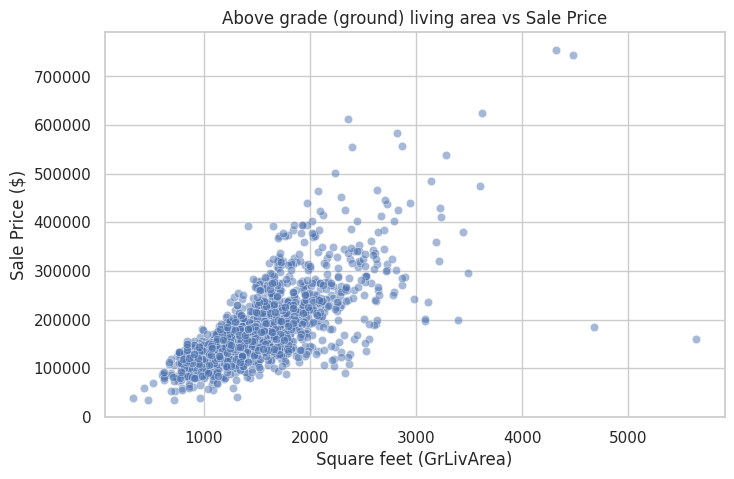

In [20]:
# let's see if linear regression will work perfectly

plt.figure(figsize=(8 , 5))
sns.scatterplot(x = Ames_data['GrLivArea'] , y = Ames_data['SalePrice'] , alpha = 0.5)
plt.title('Above grade (ground) living area vs Sale Price')
plt.xlabel('Square feet (GrLivArea)')
plt.ylabel('Sale Price ($)')
plt.show()

The creator of the dataset explicitly recommended to remove the properties with more that 4000 square feet

we are going to filter them

In [21]:
# Filter the outliers
Ames_data = Ames_data[Ames_data['GrLivArea'] < 4000]

### Building the Models

Two models will be built to compare which one performs the best:
A linear model and a random forest model

In [31]:
Ames_data_cleaned = Ames_data[Ames_data['GrLivArea'] < 4000].copy()

num_features = ['OverallQual' , 'GrLivArea' ,'GarageCars' , 'GarageArea' ,
                'TotalBsmtSF' , '1stFlrSF' , 'FullBath' , 'TotRmsAbvGrd' ,
                'YearBuilt' , 'YearRemodAdd' , 'Fireplaces' , 'BsmtFinSF1' , 'LotFrontage'
                ]
cat_features = ['ExterQual' , 'KitchenQual' , 'BsmtQual' , 'GarageFinish' ,
                'FireplaceQu' , 'MasVnrType' , 'Foundation' , 'CentralAir'  ,
                'HeatingQC' , 'GarageType' , 'Neighborhood' , 'BsmtFinType1' , 'BsmtExposure'
                ]

X = Ames_data_cleaned[num_features + cat_features]
y = np.log1p(Ames_data_cleaned['SalePrice'])

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=42)

# the preprocessing pipeline
# Numerical features
num_transformer = Pipeline(steps=[('scaler' , StandardScaler())])

# Categorical features
cat_transformer = Pipeline(steps=[('onehot' , OneHotEncoder(handle_unknown= 'ignore' , sparse_output=False))])

# Combination of both transformer
preprocessor = ColumnTransformer(transformers=[
    ('num' , num_transformer , num_features),
    ('cat' , cat_transformer , cat_features)
])


# Linear Regression model

lr_pipeline = Pipeline(steps=[
    ('preprocessor' , preprocessor),
    ('model' , LinearRegression())
])

lr_pipeline.fit(X_train , y_train)

# Random Forest Model

rf_pipeline = Pipeline(steps=[
    ('preprocessor' , preprocessor),
    ('model' , RandomForestRegressor(n_estimators=100 , random_state=42 , n_jobs=-1))
])
rf_pipeline.fit(X_train , y_train)

# Evaluation

def evaluate_model(pipeline , X_test , y_test):
  preds = pipeline.predict(X_test)
  r2 = r2_score(y_test , preds)
  rmse = root_mean_squared_error(y_test , preds)
  return r2 , rmse
lr_r2 , lr_rmse = evaluate_model(lr_pipeline , X_test , y_test)
rf_r2 , rf_rmse = evaluate_model(rf_pipeline , X_test , y_test)

# A table for the results

results_models = pd.DataFrame({
    'Model' : ['Linear Regression' , 'Random Forest'] ,
    'R Square Score': [f'{lr_r2 : .4f}' , f'{rf_r2 : .4f}'],
    'RMSE': [f'{lr_rmse : .4f}' , f'{rf_rmse : .4f}'],
})

print('TABLE WITH TRANSFORMATIONS AND SCALING')
print(results_models.to_string(index = False))

TABLE WITH TRANSFORMATIONS AND SCALING
            Model R Square Score    RMSE
Linear Regression         0.8862  0.1341
    Random Forest         0.8386  0.1597
